## Training and Evaluation

In [2]:
%pip install nbformat

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 26.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
%%capture
%run Preprocessing.ipynb

In [4]:
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold,GridSearchCV

from sklearn.metrics import  accuracy_score,f1_score, balanced_accuracy_score, classification_report, ConfusionMatrixDisplay

# reusing the data from the previous notebook
x_tr_clean = x_tr_clean
y_tr = y_tr
y_trv = y_trv
y_v = y_v
x_v_clean = x_v_clean
x_te_clean = x_te_clean
y_te = y_te
num_cols = num_cols
total_pipe = total_pipe
x_trv = x_trv

In [5]:
pca = PCA(n_components=0.9)
x_pca_tr = pca.fit_transform(x_tr_clean) 
x_pca_v = pca.transform(x_v_clean)

# Now our data is scaled and with reduced dimensions
def majority(y_tr,x_v):
   majority = np.unique_counts(y_tr).values[np.argmax(np.unique_counts(y_tr).counts)]
   pred = np.ones(len(x_v))
   return majority*pred
print(f"Majority class macro f1 score is {f1_score(y_v, majority(y_tr,x_pca_v),average="macro"):.2f}")

LR_model = LogisticRegression(random_state=10)
LR_model.fit(x_pca_tr,y_tr)
print(f"Multinomial Logistic Regression macro f1 score is  {f1_score(y_v, LR_model.predict(x_pca_v),average="macro"):.2f} ")
Tree_model = DecisionTreeClassifier(random_state=10)
Tree_model.fit(x_pca_tr,y_tr)
print(f"Decision Tree macro f1 score is  {f1_score(y_v, Tree_model.predict(x_pca_v),average="macro"):.2f} ")
RFC_model = RandomForestClassifier(random_state=10)
RFC_model.fit(x_pca_tr,y_tr)
print(f"Random Forest macro f1 score is  {f1_score(y_v, RFC_model.predict(x_pca_v),average="macro"):.2f} ")

Majority class macro f1 score is 0.22
Multinomial Logistic Regression macro f1 score is  0.86 
Decision Tree macro f1 score is  0.72 
Random Forest macro f1 score is  0.84 


In [6]:
kfold = StratifiedKFold(n_splits=5, random_state=10, shuffle=True)

def param_tuning(model, param_grid, name):

    pipe = Pipeline([("preprocess",total_pipe),("pca",pca),("model",model)])
    grid = GridSearchCV(pipe,param_grid,cv = kfold,scoring="f1_macro")
    grid.fit(x_trv,y_trv) #using x_trv since validation will automatically split train and valid
    mean_f1 = grid.cv_results_["mean_test_score"][grid.best_index_]
    std_f1 = grid.cv_results_["std_test_score"][grid.best_index_]
    param = list(grid.best_params_.keys())[0].replace("model__","")
    value = list(grid.best_params_.values())[0]
    print(f"For {name} best parameter is {param} = {value}\nThis gives mean macro F1 score of {mean_f1:.3f} with deviation of {std_f1:.3f}")


param_tuning(LogisticRegression(random_state=10),{"model__C": [0.01, 0.1, 1.0, 10.0]} ,"Logistic Regression")
param_tuning(DecisionTreeClassifier(random_state=10),{"model__max_depth": [1, 3, 7, None]} ,"Decision Tree")
param_tuning(RandomForestClassifier(random_state=10),{"model__n_estimators": [50, 100, 200]},"Random Forest" )

For Logistic Regression best parameter is C = 1.0
This gives mean macro F1 score of 0.801 with deviation of 0.070
For Decision Tree best parameter is max_depth = 3
This gives mean macro F1 score of 0.708 with deviation of 0.128
For Random Forest best parameter is n_estimators = 200
This gives mean macro F1 score of 0.759 with deviation of 0.049


Majority baseline test macro F1: 0.218
Logistic Regression: accuracy 0.949, balanced accuracy 0.960, macro F1 0.960
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00         5
         1.0       0.95      0.95      0.95        19
         2.0       0.93      0.93      0.93        15

    accuracy                           0.95        39
   macro avg       0.96      0.96      0.96        39
weighted avg       0.95      0.95      0.95        39



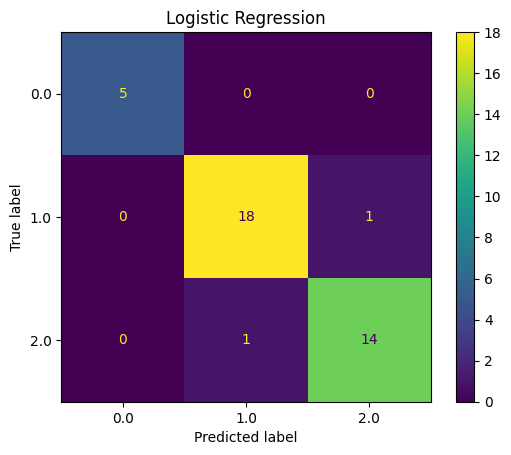

Decision Tree: accuracy 0.897, balanced accuracy 0.916, macro F1 0.899
              precision    recall  f1-score   support

         0.0       0.83      1.00      0.91         5
         1.0       0.86      0.95      0.90        19
         2.0       1.00      0.80      0.89        15

    accuracy                           0.90        39
   macro avg       0.90      0.92      0.90        39
weighted avg       0.91      0.90      0.90        39



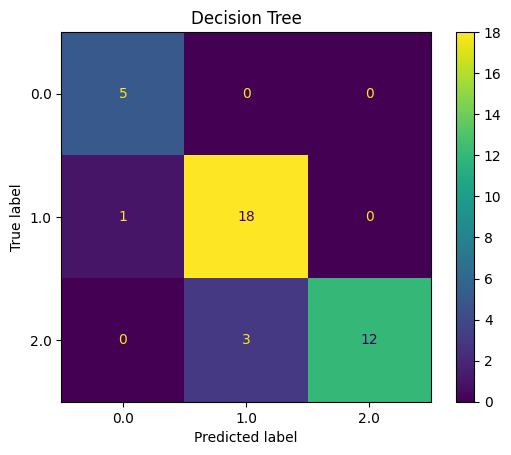

Random Forest: accuracy 0.949, balanced accuracy 0.911, macro F1 0.935
              precision    recall  f1-score   support

         0.0       1.00      0.80      0.89         5
         1.0       0.90      1.00      0.95        19
         2.0       1.00      0.93      0.97        15

    accuracy                           0.95        39
   macro avg       0.97      0.91      0.93        39
weighted avg       0.95      0.95      0.95        39



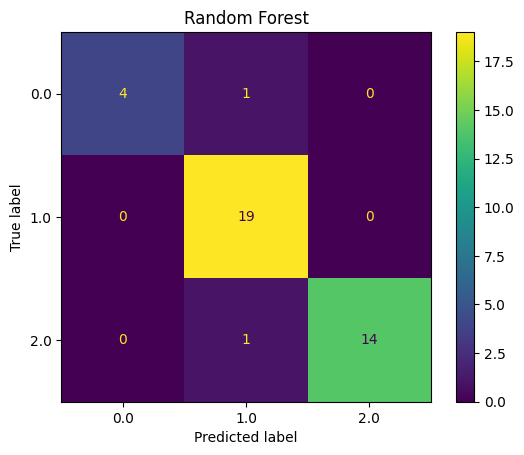

In [ ]:
def evaluate(model, name, x_te_clean = x_te_clean, y_te = y_te):

    model.fit(x_pca_tr, y_tr)
    y_pred = model.predict(pca.transform(x_te_clean))

    acc = accuracy_score(y_te, y_pred)
    bal_acc = balanced_accuracy_score(y_te, y_pred)
    F1 = f1_score(y_te, y_pred, average = "macro")
    per_class_prec = classification_report(y_te, y_pred, zero_division=0)

    print(f"{name}: accuracy {acc:.3f}, balanced accuracy {bal_acc:.3f}, macro F1 {F1:.3f}")
    print(per_class_prec)

    ConfusionMatrixDisplay.from_predictions(y_te, y_pred)
    plt.title(name)
    if name == "Logistic Regression":
        plt.savefig("../deliverables/report/figures/confusion_matrix.png", dpi=200)
    plt.show()

    return y_pred

# Final models based on hyperparam tuning
final_models = {
    "Logistic Regression": LogisticRegression(random_state=10, C=1),
    "Decision Tree": DecisionTreeClassifier(random_state=10, max_depth=3),
    "Random Forest": RandomForestClassifier(random_state=10, n_estimators=200),
}

print(f"Majority baseline test macro F1: {f1_score(y_te, majority(y_tr, x_te_clean), average = "macro"):.3f}")
test_preds = {name: evaluate(model, name) for name, model in final_models.items()}
lr_pred = test_preds["Logistic Regression"]

In [8]:
x_num_clean = x_tr_clean[num_cols] # no data leakage between num and categorical columns
cat_cols_new = x_tr_clean.columns[~np.isin(x_tr_clean.columns,num_cols)] #different from original cat_cols due to OHE
x_cat_clean = x_tr_clean[cat_cols_new] # missing indicator columns count towards categorical features
x_num_pca = pca.fit_transform(x_num_clean)
LR_model.fit(x_num_pca,y_tr)
x_num_v = pca.transform(x_v_clean[num_cols])
print(f"Numerical only LR F1 score is {f1_score(y_v,LR_model.predict(x_num_v),average='macro')}")

pca_cat = PCA(n_components=0.9) 
x_cat_pca = pca_cat.fit_transform(x_cat_clean)
LR_model.fit(x_cat_pca,y_tr)
x_cat_v = pca_cat.transform(x_v_clean[cat_cols_new])
print(f"Categorical only LR F1 score is {f1_score(y_v,LR_model.predict(x_cat_v),average='macro')}")

x_combined_pca = pca.fit_transform(x_tr_clean)
LR_model.fit(x_combined_pca,y_tr)
x_combined_v = pca.transform(x_v_clean)
print(f"Combined LR F1 score is {f1_score(y_v,LR_model.predict(x_combined_v),average='macro')}")

region_cols = [x for x in x_tr_clean.columns if "Region"  in x]
x_no_region_pca = pca.fit_transform(x_tr_clean.drop(columns=region_cols))
LR_model.fit(x_no_region_pca,y_tr)
x_no_region_v = pca.transform(x_v_clean.drop(columns=region_cols))
print(f"Without regions,  LR F1 score is {f1_score(y_v,LR_model.predict(x_no_region_v),average='macro')}")

sector_cols = [x for x in x_tr_clean.columns if "Sector"  in x]
x_no_sector_pca = pca.fit_transform(x_tr_clean.drop(columns=sector_cols))
LR_model.fit(x_no_sector_pca,y_tr)
x_no_sector_v = pca.transform(x_v_clean.drop(columns=sector_cols))
print(f"Without dominant sector,  LR F1 score is {f1_score(y_v,LR_model.predict(x_no_sector_v),average='macro')}")

Numerical only LR F1 score is 0.8107031857031858
Categorical only LR F1 score is 0.6352657004830918
Combined LR F1 score is 0.860377973281199
Without regions,  LR F1 score is 0.8645673323092677
Without dominant sector,  LR F1 score is 0.860377973281199


In [ ]:
# Misclassified countries
countries = pd.read_csv("../data/dataset.csv")["Country"]
wrong = (lr_pred != y_te)
pd.DataFrame({"Country": countries[y_te.index[wrong]], "True": y_te[wrong], "Predicted": lr_pred[wrong]})

,Country,True,Predicted
114,MDA,1.0,2.0
177,TTO,2.0,1.0


In [ ]:
# LR coefficients without PCA
lr = LogisticRegression(random_state = 10, C = 1, max_iter = 1000).fit(x_tr_clean, y_tr)
pd.DataFrame(lr.coef_.T, index = x_tr_clean.columns, columns = ["Low", "Medium/High", "Very High"]).round(2).sort_values("Very High")

,Low,Medium/High,Very High
Infant_mortality,0.97,0.81,-1.78
Agriculture,0.74,0.36,-1.09
Region_SAS,-0.04,0.77,-0.73
Region_MEA,1.02,-0.65,-0.36
Dominant_Sector_Services,-0.15,0.36,-0.21
missingindicator_Trade,-0.51,0.69,-0.18
Unemployment_total,-0.15,0.30,-0.15
missingindicator_Services,0.14,-0.05,-0.09
missingindicator_Industry,0.14,-0.05,-0.09
missingindicator_Agriculture,0.14,-0.05,-0.09


In [ ]:
# Permutation Importance (tbd)